# AI-Powered Customer Segmentation & Marketing Recommendation System

### **Overview**
This project focuses on segmenting a retail store's customer base using **K-Means Clustering**. By analyzing demographic data and spending patterns, we categorize customers into distinct groups to help businesses tailor their marketing strategies and improve customer retention.

### **Objectives**
- Group customers based on features like Age, Annual Income, and Spending Score.
- Determine the optimal number of clusters using mathematical methods.
- Provide actionable business insights and marketing recommendations for each segment.
- Deploy a **Gradio** web interface for real-time predictions.

## 1. Import Libraries
We begin by importing the essential libraries for data manipulation, visualization, machine learning, and deployment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import joblib
import warnings

# Try to install gradio if not available
try:
    import gradio as gr
except ImportError:
    !pip install -q gradio
    import gradio as gr

# Configure settings
warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
%matplotlib inline

## 2. Load the Dataset
We load the `Mall_Customers.csv` file into a Pandas DataFrame.

In [2]:
# Load dataset
try:
    df = pd.read_csv('Mall_Customers.csv')
    print("Dataset loaded successfully!")
    display(df.head())
except FileNotFoundError:
    print("Error: Mall_Customers.csv not found in the current directory.")

Dataset loaded successfully!


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Exploratory Data Analysis (EDA)
We need to understand the structure of the data, check for missing values, and analyze distributions.

In [3]:
# Basic Information
print("--- Data Info ---")
df.info()

print("\n--- Descriptive Statistics ---")
display(df.describe())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicates ---")
print(f"Duplicate rows: {df.duplicated().sum()}")

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

--- Descriptive Statistics ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



--- Missing Values ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- Duplicates ---
Duplicate rows: 0


### 3.1 Visualizing Distributions
Let's look at how Age, Income, and Spending Score are distributed across our customer base.

In [4]:
fig = px.histogram(df, x="Age", nbins=20, title="Distribution of Customer Age", marginal="box")
fig.show()

fig = px.histogram(df, x="Annual Income (k$)", nbins=20, title="Distribution of Annual Income", color="Gender", marginal="rug")
fig.show()

fig = px.scatter(df, x="Annual Income (k$)", y="Spending Score (1-100)", color="Gender",
                 title="Income vs Spending Score", size="Age")
fig.show()

## 4. Feature Selection & Preprocessing
K-Means is sensitive to scale, so we must normalize our numeric features.

In [5]:

features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

# Encode Gender for potential use later
le = LabelEncoder()
df['Gender_Encoded'] = le.fit_transform(df['Gender'])

# Scaling the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data scaled successfully. Preview of scaled data:")
print(X_scaled[:5])

Data scaled successfully. Preview of scaled data:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


## 5. Finding the Optimal Number of Clusters (K)
We use the **Elbow Method** (WCSS) and **Silhouette Scores** to find the best value for K.

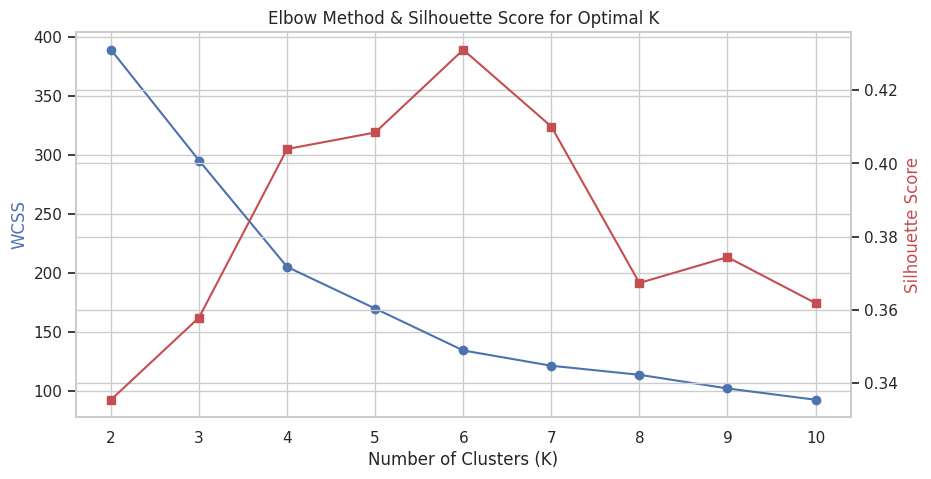

In [6]:
wcss = []
silhouette_avg = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_avg.append(silhouette_score(X_scaled, kmeans.labels_))

# Plotting Elbow
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(range(2, 11), wcss, marker='o', color='b', label='WCSS (Elbow)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('WCSS', color='b')

# Plotting Silhouette Score on same graph
ax2 = ax1.twinx()
ax2.plot(range(2, 11), silhouette_avg, marker='s', color='r', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')

plt.title('Elbow Method & Silhouette Score for Optimal K')
plt.show()

## 6. Model Training & Cluster Assignment
Based on the analysis above, we choose an optimal K (usually 5 or 6 for this dataset) and train our model.

In [7]:
OPTIMAL_K = 5 # Adjusted based on common Mall Customer results

kmeans_model = KMeans(n_clusters=OPTIMAL_K, init='k-means++', random_state=42)
df['Cluster'] = kmeans_model.fit_predict(X_scaled)

# Evaluation Metrics
print(f"Silhouette Score: {silhouette_score(X_scaled, df['Cluster']):.3f}")
print(f"Davies-Bouldin Index: {davies_bouldin_score(X_scaled, df['Cluster']):.3f}")
print(f"Calinski-Harabasz Score: {calinski_harabasz_score(X_scaled, df['Cluster']):.3f}")

Silhouette Score: 0.408
Davies-Bouldin Index: 0.889
Calinski-Harabasz Score: 123.419


## 7. Cluster Visualization & Interpretation
Let's visualize the segments in 3D and name them based on their characteristics.

In [8]:
fig = px.scatter_3d(df, x='Age', y='Annual Income (k$)', z='Spending Score (1-100)',
                    color='Cluster', opacity=0.8,
                    title="3D Customer Segments")
fig.show()

# Cluster Analysis
cluster_summary = df.groupby('Cluster')[features].mean()
cluster_summary['Count'] = df['Cluster'].value_counts()


cluster_names = {
    0: "Frugal (Low Income, Low Spend)",
    1: "Average (Mid Income, Mid Spend)",
    2: "Target (High Income, High Spend)",
    3: "Sensible (High Income, Low Spend)",
    4: "Careless (Low Income, High Spend)"
}

df['Segment'] = df['Cluster'].map(cluster_names)
display(cluster_summary)

,Age,Annual Income (k$),Spending Score (1-100),Count
Cluster,,,,
0,55.275862,47.620690,41.706897,58
1,32.875000,86.100000,81.525000,40
2,25.769231,26.115385,74.846154,26
3,26.733333,54.311111,40.911111,45
4,44.387097,89.774194,18.483871,31


## 8. Business Strategy & Recommendations
For each segment, we define specific marketing actions.

In [9]:
strategies = {
    "Target (High Income, High Spend)": "Focus on VIP loyalty programs and new premium arrivals.",
    "Sensible (High Income, Low Spend)": "Send personalized discount offers for high-value items.",
    "Average (Mid Income, Mid Spend)": "Regular newsletters and cashback incentives for repeat visits.",
    "Frugal (Low Income, Low Spend)": "Promotional sales, clearance events, and budget-friendly bundles.",
    "Careless (Low Income, High Spend)": "Impulse-buy alerts and short-term trend-based marketing."
}

# Apply strategies to the dataframe view
df['Marketing_Strategy'] = df['Segment'].map(strategies)
display(df[['CustomerID', 'Segment', 'Marketing_Strategy']].head())

,CustomerID,Segment,Marketing_Strategy
0,1,"Target (High Income, High Spend)",Focus on VIP loyalty programs and new premium ...
1,2,"Target (High Income, High Spend)",Focus on VIP loyalty programs and new premium ...
2,3,"Sensible (High Income, Low Spend)",Send personalized discount offers for high-val...
3,4,"Target (High Income, High Spend)",Focus on VIP loyalty programs and new premium ...
4,5,"Target (High Income, High Spend)",Focus on VIP loyalty programs and new premium ...


## 9. Save Model & Predictor Function
We save our assets and create a reusable function for our UI.

In [10]:
# Save assets
joblib.dump(kmeans_model, 'kmeans_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

def predict_segment(age, income, score):
    # Load and scale input
    data = np.array([[age, income, score]])
    scaled_data = scaler.transform(data)

    # Predict
    cluster = kmeans_model.predict(scaled_data)[0]
    segment = cluster_names[cluster]
    strategy = strategies[segment]

    return segment, strategy

## 10. Gradio Deployment
Finally, we build the interactive interface.

In [11]:
def gradio_interface(age, income, score):
    seg, strat = predict_segment(age, income, score)
    return f"**Segment:** {seg}\n\n**Strategy:** {strat}"

interface = gr.Interface(
    fn=gradio_interface,
    inputs=[
        gr.Slider(18, 100, label="Age"),
        gr.Number(label="Annual Income (k$)"),
        gr.Slider(1, 100, label="Spending Score (1-100)")
    ],
    outputs="markdown",
    title="Customer Segmentation AI",
    description="Enter customer details to generate AI-driven marketing insights.",
    theme="soft"
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d019405a4988b5b584.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
